# Composite objective-components figure

This notebook reads `CURVE_Trials-Revised.xlsx`, averages the results by problem size, and produces one publication-ready figure with four subplots: total objective, delay, travel, and priority-weighted uncovered penalty.

Place the workbook in the same directory as this notebook, in an `upload` subdirectory, or update `DATA_FILE` below.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

In [2]:
# Locate and read the revised workbook.
WORKBOOK_NAME = 'CURVE_Trials-Revised.xlsx'
candidate_paths = [
    Path.cwd() / WORKBOOK_NAME,
    Path.cwd() / 'upload' / WORKBOOK_NAME,
    Path('/content') / WORKBOOK_NAME,  # Google Colab
]

DATA_FILE = next((p for p in candidate_paths if p.exists()), None)
if DATA_FILE is None:
    matches = list(Path.cwd().glob(f'**/{WORKBOOK_NAME}'))
    DATA_FILE = matches[0] if matches else None
if DATA_FILE is None:
    raise FileNotFoundError(
        f'Could not find {WORKBOOK_NAME}. Place it beside the notebook or set DATA_FILE manually.'
    )

# Row 5 of the worksheet contains the actual column headers.
results = pd.read_excel(DATA_FILE, sheet_name='Results', header=4)
results = results.loc[results['Instance'].notna()].copy()

numeric_columns = [
    'Patients', 'Dynamic %',
    'Gurobi ZT', 'Gurobi Zd', 'Gurobi Zt2', 'Gurobi Zu',
    'GA Best ZT', 'GA Best Zd', 'GA Best Zt3', 'GA Best Zu',
    'RH ZT', 'RH Zd', 'RH Zt4', 'RH Zu',
]
for column in numeric_columns:
    results[column] = pd.to_numeric(results[column], errors='coerce')

print(f'Workbook: {DATA_FILE}')
print(f'Instance rows loaded: {len(results)}')

Workbook: C:\Users\sadra\Downloads\PythonCodes-HHC\CURVE_Trials-Revised.xlsx
Instance rows loaded: 100


In [3]:
# Average over the five dynamic-demand proportions and five instance seeds.
# GA values correspond to the best of five runs for each instance.
sizes = [20, 40, 60, 80]
method_columns = {
    'Gurobi': {
        'ZT': 'Gurobi ZT', 'Zd': 'Gurobi Zd',
        'Zt': 'Gurobi Zt2', 'Zu': 'Gurobi Zu',
    },
    'Genetic algorithm': {
        'ZT': 'GA Best ZT', 'Zd': 'GA Best Zd',
        'Zt': 'GA Best Zt3', 'Zu': 'GA Best Zu',
    },
    'Rolling horizon': {
        'ZT': 'RH ZT', 'Zd': 'RH Zd',
        'Zt': 'RH Zt4', 'Zu': 'RH Zu',
    },
}

records = []
for size in sizes:
    subset = results.loc[results['Patients'].eq(size)]
    record = {
        'Patients': size,
        'Instances': len(subset),
        'n_Gurobi': int(subset['Gurobi ZT'].notna().sum()),
    }
    for method, components in method_columns.items():
        for component, column in components.items():
            record[f'{method}_{component}'] = subset[column].mean(skipna=True)
    records.append(record)

summary = pd.DataFrame(records)
print(summary.round(1).to_string(index=False))

 Patients  Instances  n_Gurobi  Gurobi_ZT  Gurobi_Zd  Gurobi_Zt  Gurobi_Zu  Genetic algorithm_ZT  Genetic algorithm_Zd  Genetic algorithm_Zt  Genetic algorithm_Zu  Rolling horizon_ZT  Rolling horizon_Zd  Rolling horizon_Zt  Rolling horizon_Zu
       20         25        25      711.3      211.5      499.8        0.0                 713.2                 213.0                 500.2                   0.0              2597.3               828.2               489.1              1280.0
       40         25        22     8245.6      507.5      874.4     6863.6                8978.1                 637.9                 900.2                7440.0             13998.4              1491.3               907.0             11600.0
       60         25        20    12598.3      692.5     1205.8    10700.0               14615.0                1249.6                1325.4               12040.0             20788.0              2212.3              1215.7             17360.0
       80         25        

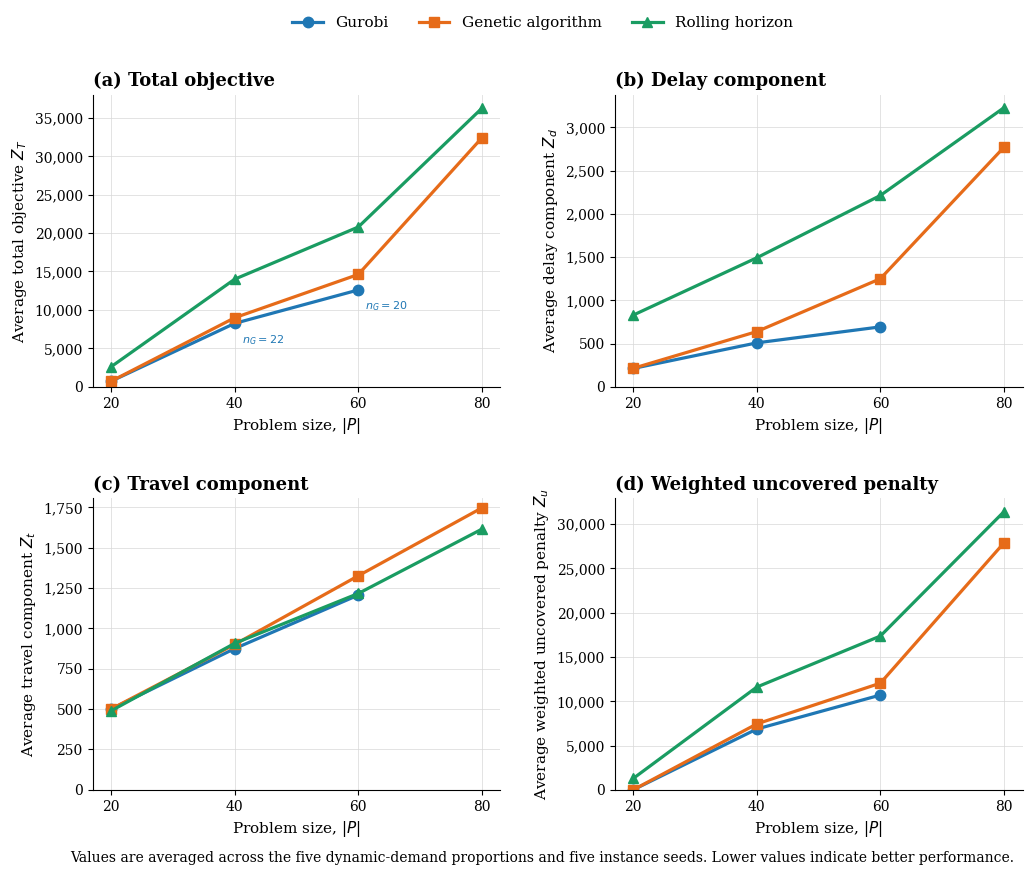

Saved: figure_objective_components_by_problem_size.pdf
Saved: figure_objective_components_by_problem_size.png


In [6]:
# Publication-ready 2 x 2 composite figure.
metric_specs = [
    ('(a) Total objective', 'ZT', r'Average total objective $Z_T$'),
    ('(b) Delay component', 'Zd', r'Average delay component $Z_d$'),
    ('(c) Travel component', 'Zt', r'Average travel component $Z_t$'),
    ('(d) Weighted uncovered penalty', 'Zu',
     r'Average weighted uncovered penalty $Z_u$'),
]

styles = {
    'Gurobi': {'color': '#1f77b4', 'marker': 'o'},
    'Genetic algorithm': {'color': '#e66b19', 'marker': 's'},
    'Rolling horizon': {'color': '#1a9c62', 'marker': '^'},
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8.8))
axes = axes.ravel()

for ax, (title, component, ylabel) in zip(axes, metric_specs):
    for method, style in styles.items():
        values = summary[f'{method}_{component}'].to_numpy(dtype=float)
        ax.plot(
            sizes, values,
            label=method,
            color=style['color'],
            marker=style['marker'],
            linewidth=2.3,
            markersize=7.5,
        )

    # Identify incomplete Gurobi samples once, in panel (a), to avoid clutter.
    if component == 'ZT':
        for _, row in summary.iterrows():
            n_g = int(row['n_Gurobi'])
            size = int(row['Patients'])
            y_value = row[f'Gurobi_{component}']
            if 0 < n_g < 25 and pd.notna(y_value):
                ax.annotate(
                    rf'$n_G={n_g}$',
                    (size, y_value),
                    xytext=(5, -14),
                    textcoords='offset points',
                    fontsize=8,
                    color=styles['Gurobi']['color'],
                )

    ax.set_title(title, loc='left', fontweight='bold')
    ax.set_xlabel('Problem size, $|P|$')
    ax.set_ylabel(ylabel)
    ax.set_xticks(sizes)
    ax.set_ylim(bottom=0)
    ax.margins(y=0.12)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax.grid(True, color='#d9d9d9', linewidth=0.65, alpha=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc='upper center',
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.995),
)
fig.text(
    0.5, 0.018,
    'Values are averaged across the five dynamic-demand proportions and five instance seeds. '
    'Lower values indicate better performance.',
    ha='center', fontsize=10,
)
fig.subplots_adjust(top=0.89, bottom=0.10, hspace=0.38, wspace=0.28)

OUTPUT_STEM = Path('figure_objective_components_by_problem_size')
fig.savefig(OUTPUT_STEM.with_suffix('.pdf'), bbox_inches='tight')
fig.savefig(OUTPUT_STEM.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f'Saved: {OUTPUT_STEM.with_suffix(".pdf")}')
print(f'Saved: {OUTPUT_STEM.with_suffix(".png")}')